# Exploratory Data Analysis of Fitbit data for DATA2007
#### Author: Samuel Furneaux
#### Last updated: 16/10/2026

## Purpose
For the group task we were given several CSV's containing Fitbit data. In this notebook I present the Exploratory Data Analysis (EDA) undertaken on the following CSV's:
- heartrate_seconds_merged.csv
- minuteMETsNarrow_merged.csv
- sleepDay_merged.csv

The purpose of this analysis is to develop an understanding of the data contained within, the data types, its completness and typical ranges to expect. This will help to inform the development of our dashboard.

In [31]:
## Import libraries
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib_venn import venn3


## Import data
data_path = Path.cwd().parent / "datafolder"
data_path = Path.cwd().parent / "datafolder"

data_sleep = pd.read_csv(data_path / "sleepDay_merged.csv")
data_hr    = pd.read_csv(data_path / "heartrate_seconds_merged.csv")
data_METs  = pd.read_csv(data_path / "minuteMETsNarrow_merged.csv")

## Clean MET data - appears to be a magnitude of 10 too large:
# Online summary of MET's suggest they should be around the 3-10 mark. 
data_METs['METs'] = data_METs['METs']/10

## Standardise time column and set date-time column in each as a date-time object.
for df in [data_sleep,data_hr,data_METs]:
    df.rename({'SleepDay':'Time','ActivityMinute':'Time'}, axis = 1, inplace=True)
    df['Time'] = pd.to_datetime(df['Time'], format="%m/%d/%Y %I:%M:%S %p")

## Function for repeated summaries:
def summarise(data_name, df, columns):
    """
    Placeholder
    """

    print(f"Summary of {data_name}")
    print(f"\n {data_name} has {len(df.columns)} columns: {df.columns}.")
    print(f"\nNumber of rows in data: {len(df)}.")
    print(f"\nNumber of duplicates in data: {df.duplicated().sum()}.")
    print(f"\nNumber of rows with missing values:\n{df.isnull().sum()}.")
    print(f"\nData head:\n {df.head()}.")

    print(f"\n\nSUMMARY OF PARTICIPANT ID's:")
    print(f"\n{df.Id.nunique()} unique participants are captured in the data.")
    print(f"\nThe distribution of measurements by user:\n {df.Id.value_counts()}")

    print(f"\n\nSUMMARY OF TIMESTAMPS:")
    print(f"\n\nThe data ranges from {df.Time.min()} to {df.Time.max()}.")
    print(f"\nThe distribution of measurements by day:\n {df.Time.dt.normalize().value_counts()}")

    print(f"\n\nSUMMARY OF data:")
    print(f"\n\nThe summary of the numerical columns ({columns} are: {df[columns].describe([.1, .25, .5, .75, .9, .99])}")
  
    print(f"\n-----------------------------\n END")

## heartrate_seconds_merged.csv

Contains hear rate data from the users:
- Value - the participants heart rate captured at the second level of granularity. Assumed to be beats per minute (BPM)

In [2]:
summarise("Heart rate data", data_hr, ['Value'])

Summary of Heart rate data

 Heart rate data has 3 columns: Index(['Id', 'Time', 'Value'], dtype='str').

Number of rows in data: 2483658.

Number of duplicates in data: 0.

Number of rows with missing values:
Id       0
Time     0
Value    0
dtype: int64.

Data head:
            Id                Time  Value
0  2022484408 2016-04-12 07:21:00     97
1  2022484408 2016-04-12 07:21:05    102
2  2022484408 2016-04-12 07:21:10    105
3  2022484408 2016-04-12 07:21:20    103
4  2022484408 2016-04-12 07:21:25    101.


SUMMARY OF PARTICIPANT ID's:

14 unique participants are captured in the data.

The distribution of measurements by user:
 Id
4020332650    285461
6962181067    266326
5553957443    255174
4388161847    249748
5577150313    248560
8877689391    228841
4558609924    192168
6117666160    158899
2022484408    154104
2347167796    152683
7007744171    133592
8792009665    122841
6775888955     32771
2026352035      2490
Name: count, dtype: int64


SUMMARY OF TIMESTAMPS:


The data

Text(0.5, 0, 'Heart rate (BPM)')

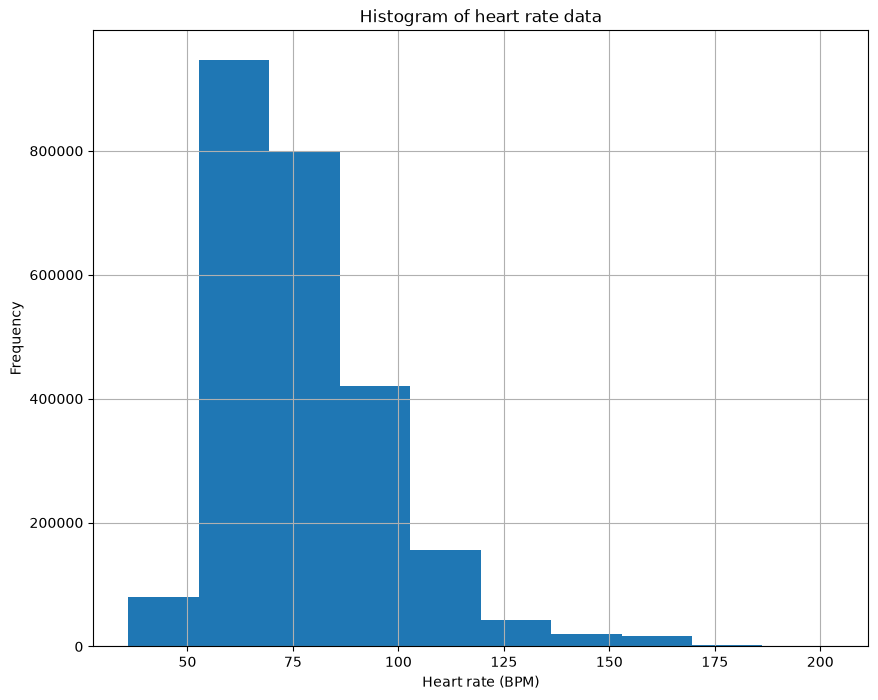

In [15]:
pd.set_option("display.float_format", "{:.4f}".format)
data_hr.Value.hist(figsize=(10,8))
plt.title('Histogram of heart rate data')
plt.ylabel('Frequency')
plt.xlabel('Heart rate (BPM)')

## Summary of heart rate data:
Contains heartrates captured at a 5 second interval for several users. To note:
- Some heart rates appear very large (e.g., 200BPM+) - may want to filter out.
- Two users (6775888955 & 2026352035) have significantly fewer samples than the others - may consider removing.

## sleepDay_merged.csv

Contains sleep data from the users:
- TotalSleepRecords -> Number of times the participant slept during the data collection period.
- TotalMinutesAsleep -> Number of minutes the participant slept during the data collection period.
- TotalTimeInBed -> Number of miniutes (assumed) the participant spent in bed during the data collection period.

In [4]:
summarise("Sleep data", data_sleep, ['TotalSleepRecords','TotalMinutesAsleep','TotalTimeInBed'])

Summary of Sleep data

 Sleep data has 5 columns: Index(['Id', 'Time', 'TotalSleepRecords', 'TotalMinutesAsleep',
       'TotalTimeInBed'],
      dtype='str').

Number of rows in data: 413.

Number of duplicates in data: 3.

Number of rows with missing values:
Id                    0
Time                  0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64.

Data head:
            Id       Time  TotalSleepRecords  TotalMinutesAsleep  \
0  1503960366 2016-04-12                  1                 327   
1  1503960366 2016-04-13                  2                 384   
2  1503960366 2016-04-15                  1                 412   
3  1503960366 2016-04-16                  2                 340   
4  1503960366 2016-04-17                  1                 700   

   TotalTimeInBed  
0             346  
1             407  
2             442  
3             367  
4             712  .


SUMMARY OF PARTICIPANT ID's:

24 unique participants are captured 

Text(0, 0.5, 'Time spent asleep (minutes)')

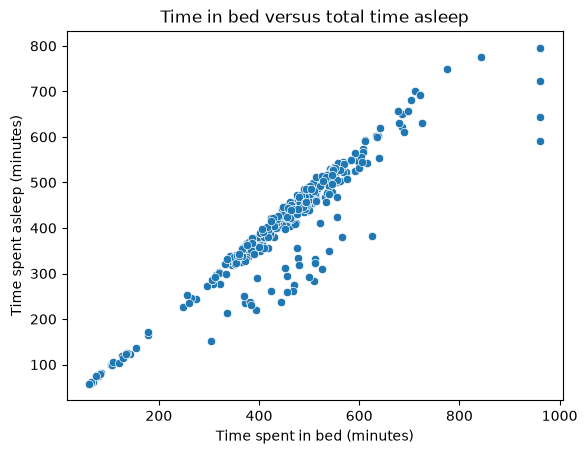

In [17]:
sns.scatterplot(x=data_sleep.TotalTimeInBed,y=data_sleep.TotalMinutesAsleep)
plt.title('Time in bed versus total time asleep')
plt.xlabel('Time spent in bed (minutes)')
plt.ylabel('Time spent asleep (minutes)')

In [18]:
## Does anyone ever sleep more than they spend time in bed?

max(data_sleep.TotalMinutesAsleep/data_sleep.TotalTimeInBed)

1.0

## Summary of Sleep data:
Contains summary of sleep in a day. To note:
- Dataset is uncomplete - most users have less measurements than there are days in the period. Some users are significantly undersampled
- Three duplicate entries.
- There seems to be some instances of 'naps' - sleeps < 60 mins. Should filter these out.

### minuteMETsNarrow_merged.csv

Its a measure of how high your activity rate is.

Light: < 3.0 METs; Moderate: 3.0–6.0 METs; Vigorous: > 6.0 METs

Source: https://www.healthline.com/health/what-are-mets#examples

Related to body weight

In [19]:
summarise("MET data", data_METs, ['METs'])

Summary of MET data

 MET data has 3 columns: Index(['Id', 'Time', 'METs'], dtype='str').

Number of rows in data: 1325580.

Number of duplicates in data: 0.

Number of rows with missing values:
Id      0
Time    0
METs    0
dtype: int64.

Data head:
            Id                Time   METs
0  1503960366 2016-04-12 00:00:00 1.0000
1  1503960366 2016-04-12 00:01:00 1.0000
2  1503960366 2016-04-12 00:02:00 1.0000
3  1503960366 2016-04-12 00:03:00 1.0000
4  1503960366 2016-04-12 00:04:00 1.0000.


SUMMARY OF PARTICIPANT ID's:

33 unique participants are captured in the data.

The distribution of measurements by user:
 Id
1624580081    44160
1927972279    44160
2026352035    44160
2873212765    44160
4558609924    44160
2022484408    44100
2320127002    44100
4388161847    44100
8053475328    44100
8877689391    44040
4445114986    43980
7086361926    43980
8378563200    43980
4020332650    43920
6962181067    43920
1844505072    43860
4702921684    43860
5553957443    43800
4319703577   

## Summary of Metabolic Equivalents (METs) data:
- Data recorded on a per minute basis.
- Data appeared to be out of scale - values started at 10+. Divided by 10 to remove error.
- A few IDs may be underrepresented, but 4057192912 should be removed as it is missing too many readings.

## Combining the data

The data contains participant ID's. How common are these ID's (i.e., can we merge on participant ID and time?).

There are 33 unique ID's containted across the three data.

 - There are 14 unique ID's containted in the heart rate data.

 - There are 24 unique ID's containted in the sleep data.

 - There are 33 unique ID's containted in the METs data.


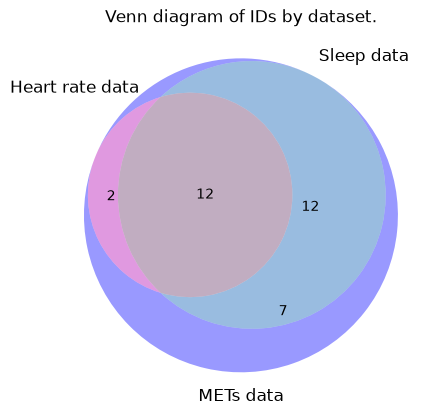

METs data is the most complete containing subsets of the others. There are 12 common IDs.


In [36]:
## Participant overlap across the three datasets
hr_ids = set(data_hr.Id)
sleep_ids = set(data_sleep.Id)
mets_ids = set(data_METs.Id)

all_ids = set((hr_ids | sleep_ids | mets_ids))

print(f"There are {len(all_ids)} unique ID's containted across the three data.")
print(f"\n - There are {len(hr_ids)} unique ID's containted in the heart rate data.")
print(f"\n - There are {len(sleep_ids)} unique ID's containted in the sleep data.")
print(f"\n - There are {len(mets_ids)} unique ID's containted in the METs data.")

venn3([hr_ids, sleep_ids, mets_ids], ('Heart rate data', 'Sleep data', 'METs data'))
plt.title('Venn diagram of IDs by dataset.')
plt.show()
print(f"METs data is the most complete containing subsets of the others. There are 12 common IDs.")

## Initial thoughts:

### Overview of data:
- We have heart rate, sleep and metabolic activity level data taken from 12 April 2016 - 12 May 2016 -> to different granularities (Heart rate is about every 5 seconds, METs per minute and sleep per day)
#### Heart rate:
- Users heart rate (BPM - assumed).
#### Sleep:
- Number of times the user slept during a 'sleeping' period.
- Total number of minutes spent sleeping.
- Total number of minutes spent in bed during a 'sleeping' period. 
#### MET:
- Users Metabolic activity rating.
- Data is assigned an ID.
- There are x common ID's - meaning the data can be used to produce a personalised health dashboard.


### Challenge:
- Not all ID's have all the data attributed to them.

### Potential use cases:
- Heart rate data is a good addition to add context to any event (e.g., heart rate during exercise/sleep/resting.)
- Sleep data could be used to relay information on how well the user slept the previous night - could build some sort of scoring system.
    - Mins in bed vs mins slept.
    - Some incoroporation of number of sleeps 
- METs could be good for exercise ('zones'). However, it might be related to body weight so some additional research is needed. 
